In [1]:
%load_ext autoreload
%autoreload 2

import sys
import importlib
from pathlib import Path
import cv2
import numpy as np
import torch
# Resolve paths
PROJECT_ROOT = Path("..").resolve()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

# Import pipeline classes and utilities
from dataset import ImageDataset
from feature_matching import FeatureMatcher
from pose_estimation import PoseEstimator
from triangulation import Triangulator
from bundle_adjustment import BundleAdjuster
from utils import build_intrinsic_matrix, export_ply
import itertools

In [2]:
# 1. Load Dataset
dataset = ImageDataset()
print(f"Loaded {len(dataset)} images.")

# 2. Build Intrinsic Matrix K
height, width = dataset[0].shape[:2]
K = build_intrinsic_matrix(width=width, height=height)

# 3. Instantiate Pipeline Modules
matcher = FeatureMatcher()
estimator = PoseEstimator(K)
triangulator = Triangulator(K)
optimizer = BundleAdjuster(K)

Loaded 179 images.


In [3]:
# 1. Pre-extract features for the entire dataset
all_kp, all_des = {}, {}
print(f"Extracting features for all {len(dataset)} images...")
for i in range(len(dataset)):
    kp, des = matcher.extract_features(dataset[i])
    all_kp[i], all_des[i] = kp, des

# 2. Push to GPU VRAM
print("Pushing all descriptors to GPU VRAM...")
all_des_gpu = {
    i: torch.tensor(des, dtype=torch.float32, device="cuda") 
    for i, des in all_des.items()
}

# 3. Build Forward Match Graph
match_graph = {}
print("Building exhaustive Match Graph across all camera pairs...")
for i, j in itertools.combinations(range(len(dataset)), 2):
    # This automatically includes Lowe's ratio test on the GPU
    good_matches = matcher.match_and_filter_gpu(all_des_gpu[i], all_des_gpu[j])
    if len(good_matches) >= 15:
        match_graph[(i, j)] = good_matches

print(f"Match Graph complete. Found {len(match_graph)} valid overlapping image pairs.")

Extracting features for all 179 images...
Pushing all descriptors to GPU VRAM...
Building exhaustive Match Graph across all camera pairs...
Match Graph complete. Found 15909 valid overlapping image pairs.


In [4]:
# 1. Choose your seed pair (e.g., 10 and 11)
seed_a, seed_b = 10, 11

# 2. Pull the EXACT features from the pre-computed memory bank
kp0, des0 = all_kp[seed_a], all_des[seed_a]
kp1, des1 = all_kp[seed_b], all_des[seed_b]
good_matches = match_graph[(seed_a, seed_b)]

# 3. Extract coordinates and build initial 3D Map
pts0, pts1 = estimator.extract_match_coordinates(kp0, kp1, good_matches)

E, ransac_mask = estimator.estimate_essential_matrix(pts0, pts1)
R1, T1 = estimator.recover_camera_pose(E, pts0, pts1, ransac_mask)

inlier_idx = (ransac_mask.ravel() == 1)
pts0_in, pts1_in = pts0[inlier_idx], pts1[inlier_idx]

P0, P1 = triangulator.construct_projection_matrices(np.eye(3), np.zeros((3, 1)))
_, P1_rel = triangulator.construct_projection_matrices(R1, T1)

pts3D_raw = triangulator.triangulate_points(P0, P1_rel, pts0_in, pts1_in)
pts3D_init, cheirality_mask = triangulator.filter_cheirality(pts3D_raw, R1, T1)

pts3D_opt, R1_opt, T1_opt, init_rmse = optimizer.optimize_2view(
    pts3D_init=pts3D_init, R_init=R1, T_init=T1,
    pts1_2d=pts0_in[cheirality_mask], pts2_2d=pts1_in[cheirality_mask]
)

print(f"Baseline Seed Initialized: {len(pts3D_opt)} 3D points | RMSE: {init_rmse:.4f} px")

# 4. Initialize Master Containers
registered_cameras = {
    seed_a: {"R": np.eye(3), "T": np.zeros((3, 1)), "kp": kp0, "des": des0},
    seed_b: {"R": R1_opt, "T": T1_opt, "kp": kp1, "des": des1}
}
global_point_cloud = pts3D_opt.copy()

des1_matched = np.array([des1[m.trainIdx] for m in good_matches])
registered_descriptors = des1_matched[inlier_idx][cheirality_mask]

print(f"Registered Map Initialized with {len(global_point_cloud)} 3D points and matching descriptors.")

Baseline Seed Initialized: 1222 3D points | RMSE: 0.1977 px
Registered Map Initialized with 1222 3D points and matching descriptors.


In [5]:
# Track which images are in the map and which are waiting
registered_img_indices = set([seed_a, seed_b]) 
unregistered_img_indices = set(range(len(dataset))) - registered_img_indices
print("Starting Dynamic Next-Best-View (NBV) Reconstruction...")

while unregistered_img_indices:
    best_idx = None
    max_shared_features = 0
    
    # 1. Next-Best-View Selection
    for cand_idx in unregistered_img_indices:
        shared_matches = 0
        for reg_idx in registered_img_indices:
            # FIX: Force dictionary lookup into the stored (smaller, larger) format!
            pair = (min(cand_idx, reg_idx), max(cand_idx, reg_idx))
            if pair in match_graph:
                shared_matches += len(match_graph[pair])
        
        if shared_matches > max_shared_features:
            max_shared_features = shared_matches
            best_idx = cand_idx
            
    if best_idx is None or max_shared_features < 15:
        print("No remaining images have sufficient overlap with the 3D map. Stopping.")
        break
        
    print(f"\n--- Selected Image {best_idx} (Overlaps: {max_shared_features} features) ---")
    
    curr_img = dataset[best_idx]
    kp_curr = all_kp[best_idx]
    des_curr = all_des[best_idx]
    
    # 2. PnP Pose Estimation 
    # (This matches against the ENTIRE expanding memory bank, allowing Image 50 to match Image 49's contributions)
    map_matches = matcher.match_and_filter_gpu(des_curr, registered_descriptors)
    
    if len(map_matches) < 15:
        print(f"Skipping Image {best_idx}: Failed 3D-to-2D correspondence check.")
        unregistered_img_indices.remove(best_idx)
        continue

    pts2D = np.float32([kp_curr[m.queryIdx].pt for m in map_matches])
    pts3D_assoc = np.float32([global_point_cloud[m.trainIdx] for m in map_matches])

    success, rvec, tvec, pnp_inliers = cv2.solvePnPRansac(
        pts3D_assoc, pts2D, K, distCoeffs=None, flags=cv2.SOLVEPNP_ITERATIVE
    )
    
    if not success or pnp_inliers is None or len(pnp_inliers) < 10:
        print(f"Skipping Image {best_idx}: PnP pose estimation failed.")
        unregistered_img_indices.remove(best_idx)
        continue

    R_curr, _ = cv2.Rodrigues(rvec)
    T_curr = tvec.reshape(3, 1)

    registered_cameras[best_idx] = {"R": R_curr, "T": T_curr, "kp": kp_curr, "des": des_curr}

    # 3. Triangulation against strongly overlapping registered cameras
    for reg_idx in list(registered_img_indices):
        pair = (min(best_idx, reg_idx), max(best_idx, reg_idx))
        
        if pair in match_graph:
            prev_cam = registered_cameras[reg_idx]
            pair_matches = match_graph[pair]
            
            # Dynamically route the keypoints to match the original query/train order
            if best_idx < reg_idx:
                pts_curr, pts_prev = estimator.extract_match_coordinates(kp_curr, prev_cam["kp"], pair_matches)
                curr_indices = [m.queryIdx for m in pair_matches]
            else:
                pts_prev, pts_curr = estimator.extract_match_coordinates(prev_cam["kp"], kp_curr, pair_matches)
                curr_indices = [m.trainIdx for m in pair_matches]
            
            P_prev = K @ np.hstack((prev_cam["R"], prev_cam["T"]))
            P_curr = K @ np.hstack((R_curr, T_curr))
            
            new_pts3D_raw = triangulator.triangulate_points(P_prev, P_curr, pts_prev, pts_curr)
            new_pts3D_valid, v_mask = triangulator.filter_cheirality(new_pts3D_raw, R_curr, T_curr)
            
            if len(new_pts3D_valid) > 0:
                global_point_cloud = np.vstack([global_point_cloud, new_pts3D_valid])
                
                # Add these NEW features to the "memory bank" so future images can find them!
                new_des = des_curr[curr_indices][v_mask]
                registered_descriptors = np.vstack([registered_descriptors, new_des])

    # Mark as successfully processed
    registered_img_indices.add(best_idx)
    unregistered_img_indices.remove(best_idx)
    
    print(f"Registered Image {best_idx} | Total 3D Map Points: {len(global_point_cloud)}")

Starting Dynamic Next-Best-View (NBV) Reconstruction...

--- Selected Image 12 (Overlaps: 2366 features) ---
Registered Image 12 | Total 3D Map Points: 3557

--- Selected Image 13 (Overlaps: 3579 features) ---
Registered Image 13 | Total 3D Map Points: 7059

--- Selected Image 14 (Overlaps: 4868 features) ---
Registered Image 14 | Total 3D Map Points: 11814

--- Selected Image 15 (Overlaps: 5306 features) ---
Registered Image 15 | Total 3D Map Points: 16933

--- Selected Image 16 (Overlaps: 5588 features) ---
Registered Image 16 | Total 3D Map Points: 22289

--- Selected Image 17 (Overlaps: 6016 features) ---
Registered Image 17 | Total 3D Map Points: 28046

--- Selected Image 18 (Overlaps: 6336 features) ---
Registered Image 18 | Total 3D Map Points: 34077

--- Selected Image 19 (Overlaps: 7145 features) ---
Registered Image 19 | Total 3D Map Points: 40932

--- Selected Image 20 (Overlaps: 7487 features) ---
Registered Image 20 | Total 3D Map Points: 48086

--- Selected Image 21 (Over

In [6]:
output_path = PROJECT_ROOT / "outputs" / "incremental_building_reconstruction.ply"
output_path.parent.mkdir(parents=True, exist_ok=True)

export_ply(str(output_path), global_point_cloud)
print(f"Saved final 3D point cloud to: {output_path}")

Successfully exported 737515 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction.ply
Saved final 3D point cloud to: /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction.ply


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Cleaned Point Cloud: Reduced from 737515 to 737472 points.


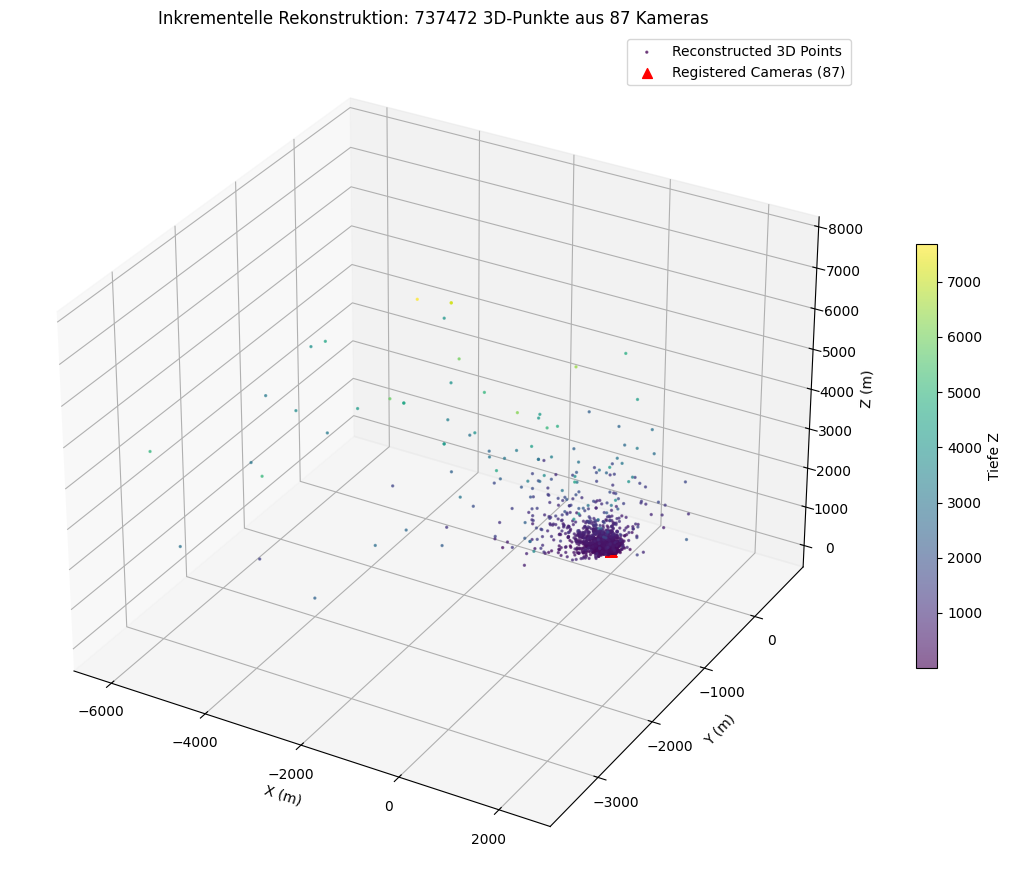

Successfully exported 737472 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/final_reconstruction.ply
Gereinigtes 3D-Modell erfolgreich gespeichert unter: /home/semi/projects/propyläen_3d_reconstruct/outputs/final_reconstruction.ply


In [7]:
import matplotlib.pyplot as plt
import numpy as np
import open3d as o3d

# 1. Clean Point Cloud (Remove Wild Distance Outliers)
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(global_point_cloud)

# Filter out points whose distance is beyond 2 standard deviations
clean_pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=50, std_ratio=2.0)
clean_points = np.asarray(clean_pcd.points)

print(
    f"Cleaned Point Cloud: Reduced from {len(global_point_cloud)} to"
    f" {len(clean_points)} points."
)

# 2. 3D Plot of Cleaned Point Cloud and Registered Cameras

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

# Visualisiere die GEREINIGTE 3D-Punktwolke (farblich nach Tiefe Z codiert)
scatter = ax.scatter(
    clean_points[:, 0],
    clean_points[:, 1],
    clean_points[:, 2],
    c=clean_points[:, 2],
    cmap="viridis",
    s=2,
    alpha=0.6,
    label="Reconstructed 3D Points",
)

# Plotting C = -R^T * T)
cam_centers = []
for idx, cam_data in registered_cameras.items():
  R_c = cam_data["R"]
  T_c = cam_data["T"]
  C = (-R_c.T @ T_c).ravel()
  cam_centers.append(C)

cam_centers = np.array(cam_centers)

# Kameras
ax.scatter(
    cam_centers[:, 0],
    cam_centers[:, 1],
    cam_centers[:, 2],
    c="red",
    s=50,
    marker="^",
    label=f"Registered Cameras ({len(cam_centers)})",
)

# Trajectory of camera pos
ax.plot(
    cam_centers[:, 0],
    cam_centers[:, 1],
    cam_centers[:, 2],
    c="red",
    linestyle="--",
    alpha=0.5,
)

# Axes
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_zlabel("Z (m)")
ax.set_title(
    f"Inkrementelle Rekonstruktion: {len(clean_points)} 3D-Punkte aus"
    f" {len(registered_cameras)} Kameras"
)
ax.legend()
fig.colorbar(scatter, ax=ax, shrink=0.5, label="Tiefe Z")

plt.tight_layout()
plt.show()

# 3. Export Cleaned Pointcloud as PLY File
output_file = PROJECT_ROOT / "outputs" / "final_reconstruction.ply"
output_file.parent.mkdir(parents=True, exist_ok=True)

export_ply(str(output_file), clean_points)
print(f"Gereinigtes 3D-Modell erfolgreich gespeichert unter: {output_file}")